In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("dataset/train.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
X = df.drop(columns=["price_range", "id"], errors="ignore")
y = df["price_range"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nPrice Categories:")
print(y.value_counts().sort_index())

Input Features Shape: (2000, 20)
Target Shape: (2000,)

Price Categories:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1600, 20)
Testing Data: (400, 20)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")
print("\nFirst 5 Scaled Samples:")
print(X_train_scaled[:5])

Feature Scaling Completed!

First 5 Scaled Samples:
[[ 1.38919326  1.011314   -1.25918898  0.98634324  1.30925256 -1.03693152
   1.58482903 -0.70458975 -1.25033529 -1.5516371   0.35023908 -0.79884868
  -1.28564151 -0.36302366 -0.78128983 -0.17762722 -0.89664506 -1.78870765
  -1.00878862 -1.02532046]
 [ 0.07840603  1.011314   -1.25918898 -1.01384584  1.77045998 -1.03693152
  -0.00345726 -1.39684863 -0.76837395  1.0731587   0.84454887  1.58230174
   1.63767503 -1.54789561  0.64708236  1.87520744  0.56094407 -1.78870765
  -1.00878862  0.97530483]
 [-1.02457347 -0.98881258  1.18747125  0.98634324 -0.0743697   0.96438384
   1.36575506  1.37218691 -1.39208862  1.51062466  0.35023908 -1.36150237
  -0.19930538  1.69898521 -0.06710374  0.506651   -0.89664506  0.55906285
   0.99128795  0.97530483]
 [ 0.38669222 -0.98881258 -1.25918898  0.98634324 -0.53557712  0.96438384
   0.10607972  1.02605747 -1.19363396 -0.67670517 -0.80315042  0.83284703
   0.27858927  1.64923164 -0.78128983  0.506651   -1.

In [6]:
model = Perceptron(
    max_iter=1000,
    eta0=0.01,
    random_state=42,
    tol=1e-3
)

model.fit(X_train_scaled, y_train)

print("Perceptron Model Trained Successfully!")

Perceptron Model Trained Successfully!


In [7]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values[:20])

print("\nPredicted Values:")
print(y_pred[:20])

Actual Values:
[3 1 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 0 1 3]

Predicted Values:
[3 1 0 1 3 2 0 0 2 0 3 0 0 1 3 3 1 0 2 3]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Perceptron Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Perceptron Model Accuracy: 69.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       100
           1       0.49      0.44      0.47       100
           2       0.48      0.52      0.50       100
           3       0.91      0.86      0.88       100

    accuracy                           0.69       400
   macro avg       0.69      0.69      0.69       400
weighted avg       0.69      0.69      0.69       400



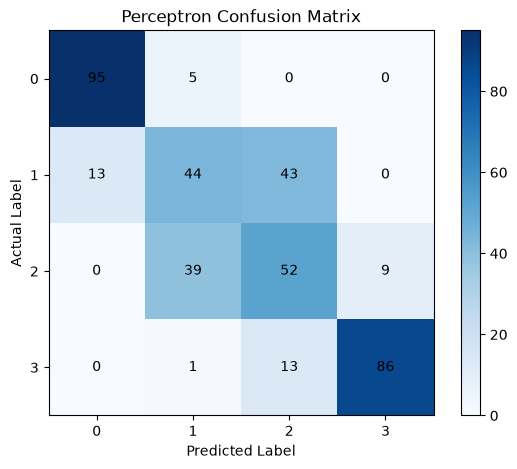

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")
plt.title("Perceptron Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1, 2, 3])
plt.yticks([0, 1, 2, 3])

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [10]:
print("Perceptron Weights:")
print(model.coef_)

print("\nPerceptron Bias:")
print(model.intercept_)

print("\nNumber of Classes:", len(model.classes_))
print("Classes:", model.classes_)

Perceptron Weights:
[[-1.46745299e-01  2.49390782e-02  5.12651778e-03  3.61909213e-02
  -1.03483415e-02 -1.36965020e-02 -4.82835609e-02 -2.21414678e-02
   7.26131457e-03 -6.08351109e-03 -2.08485451e-02 -7.67322487e-02
  -7.45917783e-02 -5.66091114e-01 -1.50351052e-02  6.94257279e-03
   1.72291590e-02  6.67647237e-03  1.39380336e-02  2.12566437e-02]
 [ 5.33577749e-03 -1.12507120e-03 -2.69973666e-02 -5.86305427e-02
   1.20490439e-02  3.62738409e-03 -1.88232463e-02 -2.64572693e-02
  -4.05343661e-02  2.05062172e-03  4.52087494e-03 -3.91726533e-02
  -2.01426766e-02 -4.46208861e-02 -2.42376906e-02 -3.69795356e-02
   5.86907373e-02 -8.95087504e-03  6.08773305e-02  2.25070345e-02]
 [-1.03539917e-03  9.21308303e-03  9.85010120e-03  1.09635364e-02
  -1.32424180e-02  1.25457457e-02 -2.00223340e-02  7.78574915e-03
   8.99212279e-03  3.62276503e-03 -4.09937286e-02 -3.16070007e-02
  -2.64015813e-02  3.03040904e-02 -4.52957651e-02 -1.26562959e-02
  -1.92242341e-02  3.12987155e-02  3.06136720e-02 -4.8